# 2_ozellik — Tatil Takvimi, Sıcaklık ve Model Özellikleri

Bu notebook Faz 2'nin özellik mühendisliği kısmını sırayla çalıştırır:

- **A.** Kurulum ve veri yükleme
- **B.** Türkiye tatil takvimi (2016-2026) ve veriyle doğrulama
- **C.** Sıcaklık özellikleri: denge sıcaklığı, HDD/CDD
- **D.** Takvim ve gecikme (lag) özellikleri
- **E.** Özellik setinin kaydı
- **F.** Resmî yük tahmin planı (`load-plan`), kıyas için
- **G.** Faz 1 açık maddesi: yeni dönemin en dar saatleri

**Girdi:** `data/tr_birlesik_saatlik.csv` (`1_veri.ipynb` çıktısı)
**Çıktılar:** `data/tr_tatil_takvimi.csv`, `data/tr_ozellikli_saatlik.csv`, `data/tr_yuk_plani_saatlik.csv`, `metrics/ozellik_ayarlari.json`, `graphs/tr_denge_sicakligi.png`

## A. Kurulum ve Veri Yükleme

`yerel_gun` (saat dilimi bilgisi çıkarılmış gün) ve `saat` sütunları, tatil ve sıcaklık gibi günlük bilgilerin saatlik veriyle eşleştirilmesi için kullanılır. Türkiye 2016'dan beri kalıcı olarak UTC+3'te olduğu için yerel saat tek anlamlıdır.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

KOK = r"C:\Deep_Learning_to_AI_Agents\Bitirme_Proje_Bonus"

df = pd.read_csv(os.path.join(KOK, "data", "tr_birlesik_saatlik.csv"))
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)
df["yerel_gun"] = df["date"].dt.tz_localize(None).dt.normalize()
df["saat"] = df["date"].dt.hour
print("Satir:", len(df), "| aralik:", df["date"].min(), "->", df["date"].max())
print("Sutunlar:", df.columns.tolist())

Satir: 91968 | aralik: 2016-04-01 00:00:00+03:00 -> 2026-09-27 23:00:00+03:00
Sutunlar: ['date', 'consumption', 'toplam', 'toplam_duz', 'gunes', 'ruzgar', 'barajli', 'dogalgaz', 'tavg_c', 'tavg_doldurma', 'marj_kapasite', 'marj_yuk', 'marj_kapasite_duz', 'marj_yuk_duz', 'eak_donem', 'eak_sicrama', 'eak_anomali', 'yerel_gun', 'saat']


## B. Türkiye Tatil Takvimi

### B1. Kaynaklar ve kurallar

**Yasal çerçeve (2429 sayılı Kanun):**
- Ramazan Bayramı, arife günü saat 13:00'ten itibaren 3,5 gün sürer.
- Kurban Bayramı, arife günü saat 13:00'ten itibaren 4,5 gün sürer.
- Cumhuriyet Bayramı 28 Ekim saat 13:00'te başlar.
- 1 Mayıs 2009'dan beri tatil (5892 sayılı Kanun).
- 15 Temmuz 2017'den beri tatil (6752 sayılı Kanun, Ekim 2016'da yürürlüğe girdi).

**Bayram tarihleri:** Türkiye'nin resmî tarihleri kullanıldı. Kaynaklar: takvim.com yıllık resmî tatil sayfaları (2016, 2017, 2019, 2021, 2022, 2023, 2024; Diyanet'e dayanıyor), bir üniversitenin 2014-2022 resmî tatil listesi (2018), Vikipedi (2020 Ramazan, 2025 Kurban), 2026 için yayımlanmış dini günler takvimleri.

**Önemli bir uyarı:** Uluslararası takvimler bazı yıllarda Türkiye'den bir gün farklı. Örneğin Vikipedi'nin listesi Ramazan Bayramı 2016 için 6 Temmuz, 2019 için 5 Haziran veriyor. Türkiye'nin resmî tarihleri ise 5 Temmuz 2016 ve 4 Haziran 2019. 2019 tarihi, Cumhurbaşkanlığı'nın idari izin yazısıyla da doğrulanıyor: tatil 3 Haziran 13:00'te başlayıp 6 Haziran'da bitiyor. Hazır tatil kütüphanelerinde de Türkiye için benzer hatalar belgelenmiş olduğundan, tablo elle kuruldu ve B4'te veriyle doğrulanıyor.

**Doğrulanmamış tek tarih:** Kurban Bayramı 2020 (31 Temmuz – 3 Ağustos) yalnızca bilinen takvime dayanıyor; B4'te veriyle kontrol ediliyor.

**İdari izinler:** Bayram tatilleri çoğu yıl, kamu çalışanlarına verilen idari izinlerle 9 güne uzatıldı. Bu izinler yalnızca kamuyu kapsıyor ve her yıl ayrı bir genelge veya yazıyla, bayramdan önce duyuruluyor. Tabloya yalnızca resmî yazısı veya resmî açıklaması bulunan 19 gün eklendi (2016, 2019, 2021, 2022, 2024, 2025, 2026). Arife sabahı verilen yarım gün izinler de `idari_izin = 1` olarak işaretli; arife öğleden sonrası zaten yasal tatil olduğu için kamu için o gün tamamen tatil.

**Kaynağı bulunamayan köprü günleri:** B4'ün ilk çalıştırmasında listelenen 2020-05-27 ve 2022-05-05/06 günleri için resmî bir izin kaydı bulunamadı. Bu yüzden tabloya eklenmedi.

In [2]:
# (yil, tur, arife tarihi, bayram gun sayisi, kaynak)
BAYRAMLAR = [
    (2016, "ramazan", "2016-07-04", 3, "takvim.com 2016"),
    (2016, "kurban",  "2016-09-11", 4, "takvim.com 2016"),
    (2017, "ramazan", "2017-06-24", 3, "takvim.com 2017"),
    (2017, "kurban",  "2017-08-31", 4, "takvim.com 2017"),
    (2018, "ramazan", "2018-06-14", 3, "universite resmi tatil listesi 2014-2022"),
    (2018, "kurban",  "2018-08-20", 4, "universite resmi tatil listesi 2014-2022"),
    (2019, "ramazan", "2019-06-03", 3, "takvim.com 2019; Cumhurbaskanligi idari izin yazisi"),
    (2019, "kurban",  "2019-08-10", 4, "takvim.com 2019"),
    (2020, "ramazan", "2020-05-23", 3, "Vikipedi"),
    (2020, "kurban",  "2020-07-30", 4, "DOGRULANMADI - B4'te veriyle kontrol"),
    (2021, "ramazan", "2021-05-12", 3, "takvim.com 2021"),
    (2021, "kurban",  "2021-07-19", 4, "takvim.com 2021"),
    (2022, "ramazan", "2022-05-01", 3, "takvim.com 2022"),
    (2022, "kurban",  "2022-07-08", 4, "takvim.com 2022"),
    (2023, "ramazan", "2023-04-20", 3, "takvim.com 2023"),
    (2023, "kurban",  "2023-06-27", 4, "takvim.com 2023"),
    (2024, "ramazan", "2024-04-09", 3, "takvim.com 2024"),
    (2024, "kurban",  "2024-06-15", 4, "takvim.com 2024"),
    (2025, "ramazan", "2025-03-29", 3, "Vikipedi"),
    (2025, "kurban",  "2025-06-05", 4, "Vikipedi"),
    (2026, "ramazan", "2026-03-19", 3, "yayimlanmis 2026 takvimleri"),
    (2026, "kurban",  "2026-05-26", 4, "yayimlanmis 2026 takvimleri"),
]

# Dogrulanmis idari izin gunleri (kamu). Arife sabahi yarim gun izinler de 1 olarak isaretli.
IDARI_IZIN = {
    "2016-07-04": "Ramazan 2016 arifesi sabahi; Basbakanlik genelgesi",
    "2016-07-08": "Ramazan 2016; Basbakanlik genelgesi",
    "2016-09-16": "Kurban 2016; Basbakanlik yazisi",
    "2019-06-03": "Ramazan 2019 arifesi sabahi; Cumhurbaskanligi yazisi",
    "2019-06-07": "Ramazan 2019; Cumhurbaskanligi yazisi",
    "2021-05-10": "Ramazan 2021; Cumhurbaskanligi yazisi",
    "2021-05-11": "Ramazan 2021; Cumhurbaskanligi yazisi",
    "2021-05-12": "Ramazan 2021 arifesi sabahi; Cumhurbaskanligi yazisi",
    "2022-07-13": "Kurban 2022; Kabine karari (TBB duyurusu)",
    "2022-07-14": "Kurban 2022; Kabine karari (TBB duyurusu)",
    "2024-04-08": "Ramazan 2024; Cumhurbaskanligi yazisi",
    "2024-04-09": "Ramazan 2024 arifesi sabahi; Cumhurbaskanligi yazisi",
    "2024-06-20": "Kurban 2024; Cumhurbaskanligi yazisi",
    "2024-06-21": "Kurban 2024; Cumhurbaskanligi yazisi",
    "2025-04-02": "Ramazan 2025; Cumhurbaskani aciklamasi",
    "2025-04-03": "Ramazan 2025; Cumhurbaskani aciklamasi",
    "2025-04-04": "Ramazan 2025; Cumhurbaskani aciklamasi",
    "2026-05-25": "Kurban 2026; Cumhurbaskanligi genelgesi",
    "2026-05-26": "Kurban 2026 arifesi sabahi; Cumhurbaskanligi genelgesi",
}

SABIT_TATILLER = [  # (ay, gun, ad, gecerli oldugu ilk yil)
    (1, 1, "Yilbasi", 1900),
    (4, 23, "Ulusal Egemenlik ve Cocuk Bayrami", 1900),
    (5, 1, "Emek ve Dayanisma Gunu", 2009),
    (5, 19, "Ataturk'u Anma, Genclik ve Spor Bayrami", 1900),
    (7, 15, "Demokrasi ve Milli Birlik Gunu", 2017),
    (8, 30, "Zafer Bayrami", 1900),
    (10, 29, "Cumhuriyet Bayrami", 1900),
]
print("Bayram kaydi:", len(BAYRAMLAR), "| idari izin:", len(IDARI_IZIN))

Bayram kaydi: 22 | idari izin: 19


### B2. Günlük tatil tablosu

Her gün için şunlar belirleniyor:
- **Tatil türü:** tam gün tatil, yarım gün (arife ve 28 Ekim; 13:00'ten sonrası), idari izin.
- **Bayram bilgisi:** bayramın türü ve kaçıncı günü olduğu.
- **Bayrama yakınlık:** bir sonraki bayram arifesine kalan gün ve son bayram gününden geçen gün sayısı; 10 gün ile sınırlı. Bu iki özellik, tatil öncesi yolculuk ve tatil sonrası dönüş dönemlerindeki tüketim etkisini yakalamak için.

In [3]:
gunler = pd.date_range("2016-01-01", "2026-12-31", freq="D")
tk = pd.DataFrame({"yerel_gun": gunler})
tk["tatil_tam"] = 0
tk["tatil_yarim"] = 0
tk["idari_izin"] = 0
tk["bayram_tur"] = 0          # 0 yok, 1 ramazan, 2 kurban
tk["bayram_gun_no"] = 0       # 1..4
tk["tatil_adi"] = ""
tk = tk.set_index("yerel_gun")

for gun in gunler:
    for ay, g, ad, ilk in SABIT_TATILLER:
        if gun.month == ay and gun.day == g and gun.year >= ilk:
            tk.loc[gun, "tatil_tam"] = 1
            tk.loc[gun, "tatil_adi"] = ad
    if gun.month == 10 and gun.day == 28:
        tk.loc[gun, "tatil_yarim"] = 1
        tk.loc[gun, "tatil_adi"] = "Cumhuriyet Bayrami arifesi"

bayram_aralik = []   # (arife, son gun)
for yil, tur, arife, n, kaynak in BAYRAMLAR:
    a = pd.Timestamp(arife)
    tk.loc[a, "tatil_yarim"] = 1
    tk.loc[a, "tatil_adi"] = f"{tur} arifesi"
    for i in range(1, n + 1):
        d = a + pd.Timedelta(days=i)
        tk.loc[d, ["tatil_tam", "bayram_tur", "bayram_gun_no"]] = [1, 1 if tur == "ramazan" else 2, i]
        tk.loc[d, "tatil_adi"] = f"{tur} {i}. gun"
    bayram_aralik.append((a, a + pd.Timedelta(days=n)))

for g, kaynak in IDARI_IZIN.items():
    tk.loc[pd.Timestamp(g), "idari_izin"] = 1

# Bayrama yakinlik (10 gun ile sinirli)
tk["bayram_once_gun"] = 10
tk["bayram_sonra_gun"] = 10
for a, son in bayram_aralik:
    for k in range(1, 11):
        d = a - pd.Timedelta(days=k)
        if d in tk.index:
            tk.loc[d, "bayram_once_gun"] = min(tk.loc[d, "bayram_once_gun"], k)
        d2 = son + pd.Timedelta(days=k)
        if d2 in tk.index:
            tk.loc[d2, "bayram_sonra_gun"] = min(tk.loc[d2, "bayram_sonra_gun"], k)
    for d in pd.date_range(a, son, freq="D"):
        tk.loc[d, ["bayram_once_gun", "bayram_sonra_gun"]] = [0, 0]

tk = tk.reset_index()
tk.to_csv(os.path.join(KOK, "data", "tr_tatil_takvimi.csv"), index=False)
print("Tam gun tatil:", int(tk["tatil_tam"].sum()), "| yarim gun:", int(tk["tatil_yarim"].sum()),
      "| idari izin:", int(tk["idari_izin"].sum()))
print(tk[tk["yerel_gun"].dt.year == 2024].query("tatil_tam == 1 or tatil_yarim == 1")[["yerel_gun", "tatil_adi"]]
      .to_string(index=False))

Tam gun tatil: 152 | yarim gun: 33 | idari izin: 19
 yerel_gun                               tatil_adi
2024-01-01                                 Yilbasi
2024-04-09                         ramazan arifesi
2024-04-10                          ramazan 1. gun
2024-04-11                          ramazan 2. gun
2024-04-12                          ramazan 3. gun
2024-04-23       Ulusal Egemenlik ve Cocuk Bayrami
2024-05-01                  Emek ve Dayanisma Gunu
2024-05-19 Ataturk'u Anma, Genclik ve Spor Bayrami
2024-06-15                          kurban arifesi
2024-06-16                           kurban 1. gun
2024-06-17                           kurban 2. gun
2024-06-18                           kurban 3. gun
2024-06-19                           kurban 4. gun
2024-07-15          Demokrasi ve Milli Birlik Gunu
2024-08-30                           Zafer Bayrami
2024-10-28              Cumhuriyet Bayrami arifesi
2024-10-29                      Cumhuriyet Bayrami


### B3. Saatlik tatil özellikleri

- `tatil_saat`: tam gün tatillerde bütün saatler, arife ve 28 Ekim'de yalnızca 13:00 ve sonrası.
- `idari_izin`: ayrı bir özellik olarak tutuluyor; yalnızca kamuyu kapsadığı için etkisi tam tatilden daha küçük beklenir.

In [4]:
df = df.drop(columns=[c for c in tk.columns if c != "yerel_gun" and c in df.columns], errors="ignore")
df = df.merge(tk, on="yerel_gun", how="left")
df["tatil_saat"] = ((df["tatil_tam"] == 1) | ((df["tatil_yarim"] == 1) & (df["saat"] >= 13))).astype(int)
print("Tatil saati:", int(df["tatil_saat"].sum()), "/", len(df))

Tatil saati: 3941 / 91968


### B4. Veriyle doğrulama

Her tatil gününün toplam tüketimi, çevresindeki normal günlerle karşılaştırılıyor. Referans değer, aynı haftanın günü olan ±7, ±14 ve ±21 gün önceki ve sonraki tatil dışı günlerin medyanı.

**Nasıl okunacak:**
- Bayram günlerinde oran belirgin şekilde düşük olmalı (örneğin 0,85'in altı). Oranı 0,97'nin üstünde olan bir bayram günü, tarihin yanlış olabileceğini gösterir.
- Köprü günü adayları: bayram çevresinde (arifeden 5 gün önce ile son günden 5 gün sonra arası) tatil olmayan ama oranı 0,90'ın altında olan hafta içi günler. Bunlar olası idari izin günleri; kaynağı bulunursa tabloya eklenecek.

In [5]:
gunluk = df.groupby("yerel_gun")["consumption"].sum()
gunluk = gunluk[df.groupby("yerel_gun").size() == 24]      # yalnizca tam gunler
ozel = set(tk.loc[(tk["tatil_tam"] == 1) | (tk["tatil_yarim"] == 1) | (tk["idari_izin"] == 1), "yerel_gun"])

def oran(g):
    ref = [g + pd.Timedelta(days=k) for k in (-21, -14, -7, 7, 14, 21)]
    ref = [r for r in ref if r in gunluk.index and r not in ozel]
    if len(ref) < 3 or g not in gunluk.index:
        return np.nan
    return gunluk[g] / np.median(gunluk[ref])

satirlar = []
for yil, tur, arife, n, kaynak in BAYRAMLAR:
    a = pd.Timestamp(arife)
    for i in range(0, n + 1):
        g = a + pd.Timedelta(days=i)
        satirlar.append({"yil": yil, "tur": tur, "gun": g.date(), "gun_no": i, "oran": oran(g)})
dog = pd.DataFrame(satirlar)
tablo_b = dog.pivot_table(index=["yil", "tur"], columns="gun_no", values="oran").round(2)
tablo_b.columns = ["arife"] + [f"{c}.gun" for c in tablo_b.columns[1:]]
print("Bayram gunlerinin tuketim orani (1,00 = normal gun):")
print(tablo_b.to_string())

supheli = dog[(dog["gun_no"] > 0) & (dog["oran"] > 0.97)]
print("\nSupheli bayram gunu (oran > 0,97):", len(supheli))
if len(supheli):
    print(supheli.to_string(index=False))

aday = []
for a, son in bayram_aralik:
    for g in pd.date_range(a - pd.Timedelta(days=5), son + pd.Timedelta(days=5), freq="D"):
        if g.dayofweek < 5 and g not in ozel:
            o = oran(g)
            if not np.isnan(o) and o < 0.90:
                aday.append({"gun": g.date(), "haftanin_gunu": g.day_name(), "oran": round(o, 2)})
print("\nKopru (idari izin) gunu adaylari:", len(aday))
if aday:
    print(pd.DataFrame(aday).to_string(index=False))

Bayram gunlerinin tuketim orani (1,00 = normal gun):
              arife  1.gun  2.gun  3.gun  4.gun
yil  tur                                       
2016 kurban    0.93   0.67   0.70   0.70   0.72
     ramazan   0.79   0.65   0.64   0.68    NaN
2017 kurban    0.75   0.64   0.69   0.80   0.77
     ramazan   0.86   0.76   0.69   0.73    NaN
2018 kurban    0.78   0.65   0.68   0.69   0.75
     ramazan   0.80   0.67   0.68   0.80    NaN
2019 kurban    0.84   0.78   0.71   0.73   0.78
     ramazan   0.81   0.65   0.65   0.69    NaN
2020 kurban    0.85   0.71   0.78   0.89   0.80
     ramazan   0.82   0.76   0.68   0.68    NaN
2021 kurban    0.85   0.71   0.73   0.75   0.77
     ramazan   0.81   0.70   0.73   0.79    NaN
2022 kurban    0.84   0.74   0.80   0.73   0.74
     ramazan   0.86   0.66   0.65   0.68    NaN
2023 kurban    0.79   0.67   0.68   0.71   0.81
     ramazan   0.78   0.65   0.69   0.82    NaN
2024 kurban    0.86   0.80   0.70   0.71   0.73
     ramazan   0.75   0.63   0.64  

### B5. Sabit tatillerin kontrolü

Hafta içine denk gelen sabit tatillerin ortalama oranı. Hafta sonuna denk gelenler zaten düşük tüketimli olduğu için karşılaştırmaya alınmıyor.

In [6]:
sabit = tk[(tk["tatil_tam"] == 1) & (tk["bayram_tur"] == 0)].copy()
sabit["oran"] = sabit["yerel_gun"].apply(oran)
sabit = sabit[sabit["yerel_gun"].dt.dayofweek < 5]
print(sabit.groupby("tatil_adi")["oran"].agg(["count", "mean", "min", "max"]).round(2).to_string())

                                         count  mean   min   max
tatil_adi                                                       
Ataturk'u Anma, Genclik ve Spor Bayrami      8  0.93  0.91  0.95
Cumhuriyet Bayrami                           6  0.88  0.86  0.93
Demokrasi ve Milli Birlik Gunu               7  0.91  0.84  0.97
Emek ve Dayanisma Gunu                       8  0.89  0.84  0.93
Ulusal Egemenlik ve Cocuk Bayrami            7  0.91  0.88  0.95
Yilbasi                                      7  0.80  0.78  0.84
Zafer Bayrami                                8  0.93  0.85  0.97


## C. Sıcaklık Özellikleri

### C1. Denge sıcaklığı (tüketimin en düşük olduğu sıcaklık)

Yalnızca normal iş günleri kullanılıyor: hafta içi, tatil değil, bayram çevresinde değil ve sıcaklığı doldurulmamış (`tavg_doldurma = 0`) günler. Günlük tüketim, 1°C'lik sıcaklık aralıklarında ortalanıyor.

Normal is gunu sayisi: 2492
          count       mean
tavg_bin                  
-2.0         20   907535.0
-1.0         39   906005.0
 0.0         50   926800.0
 1.0         44   920270.0
 2.0         64   920647.0
 3.0         77   896589.0
 4.0         94   913360.0
 5.0         90   896361.0
 6.0        106   888285.0
 7.0        100   882493.0
 8.0        103   870616.0
 9.0         93   855083.0
 10.0        79   840997.0
 11.0        82   832547.0
 12.0        86   820658.0
 13.0        84   813989.0
 14.0        86   832425.0
 15.0        71   822720.0
 16.0        83   824280.0
 17.0        64   832210.0
 18.0       100   843278.0
 19.0        78   839509.0
 20.0        87   889637.0
 21.0        74   890277.0
 22.0        87   910112.0
 23.0        73   960997.0
 24.0        95   984790.0
 25.0        85   983645.0
 26.0        90  1014363.0
 27.0        79  1037620.0
 28.0        40  1036702.0
 29.0        20  1040155.0

Tuketimin en dusuk oldugu sicaklik araligi (denge sic

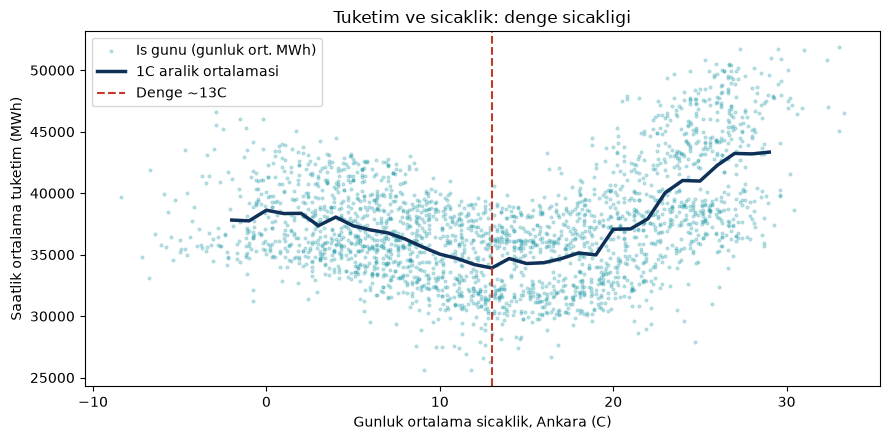

In [7]:
gd = df.groupby("yerel_gun").agg(tuketim=("consumption", "sum"), tavg=("tavg_c", "first"),
                                  dolduruldu=("tavg_doldurma", "first"), saat_sayisi=("consumption", "size"))
gd = gd.join(tk.set_index("yerel_gun")[["tatil_tam", "tatil_yarim", "idari_izin", "bayram_once_gun", "bayram_sonra_gun"]])
normal = gd[(gd.index.dayofweek < 5) & (gd["tatil_tam"] == 0) & (gd["tatil_yarim"] == 0) & (gd["idari_izin"] == 0)
            & (gd["bayram_once_gun"] > 3) & (gd["bayram_sonra_gun"] > 3) & (gd["dolduruldu"] == 0)
            & (gd["saat_sayisi"] == 24) & gd["tavg"].notna()].copy()
normal["tavg_bin"] = normal["tavg"].round()
bin_ozet = normal.groupby("tavg_bin")["tuketim"].agg(["count", "mean"])
bin_ozet = bin_ozet[bin_ozet["count"] >= 20]
denge_bin = bin_ozet["mean"].idxmin()
print("Normal is gunu sayisi:", len(normal))
print(bin_ozet.round(0).to_string())
print("\nTuketimin en dusuk oldugu sicaklik araligi (denge sicakligi, yaklasik):", denge_bin, "C")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(normal["tavg"], normal["tuketim"] / 24, s=4, alpha=0.25, color="#1B98A4", label="Is gunu (gunluk ort. MWh)")
ax.plot(bin_ozet.index, bin_ozet["mean"] / 24, color="#0F3057", linewidth=2.5, label="1C aralik ortalamasi")
ax.axvline(denge_bin, color="#C0392B", linestyle="--", label=f"Denge ~{denge_bin:.0f}C")
ax.set_xlabel("Gunluk ortalama sicaklik, Ankara (C)")
ax.set_ylabel("Saatlik ortalama tuketim (MWh)")
ax.set_title("Tuketim ve sicaklik: denge sicakligi")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(KOK, "graphs", "tr_denge_sicakligi.png"), dpi=150)
plt.show()

### C2. HDD/CDD tanımlarının karşılaştırılması

Türkiye için resmî bir baz sıcaklık bulunamadı. İki yaklaşım aynı modelle karşılaştırılıyor:

1. **Eurostat tanımı:** HDD = 18 − T (T ≤ 15°C ise, değilse 0); CDD = T − 21 (T ≥ 24°C ise, değilse 0). Bu tanımın eşik noktasında bir sıçrama (süreksizlik) olduğu biliniyor.
2. **Veriden bulunan bazlar:** HDD = max(0, bh − T), CDD = max(0, T − bc). bh ve bc, aşağıdaki modelin açıklama gücünü (R²) en yüksek yapan değerler olarak aranıyor.

**Model:** Günlük tüketim = sabit + a·HDD + b·CDD + yıl etkileri. Yıl etkileri, yıllar arasındaki tüketim artışının sıcaklık etkisiyle karışmaması için eklendi. Karar R²'ye göre veriliyor.

In [8]:
T = normal["tavg"].values
y = normal["tuketim"].values
yil_dummy = pd.get_dummies(normal.index.year, drop_first=True).values.astype(float)

def r2(hdd, cdd):
    X = np.column_stack([np.ones(len(y)), hdd, cdd, yil_dummy])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    tahmin = X @ beta
    return 1 - ((y - tahmin) ** 2).sum() / ((y - y.mean()) ** 2).sum()

hdd_e = np.where(T <= 15, 18 - T, 0.0)
cdd_e = np.where(T >= 24, T - 21, 0.0)
r2_eurostat = r2(hdd_e, cdd_e)

sonuc = []
for bh in np.arange(10, 22.5, 0.5):
    for bc in np.arange(14, 26.5, 0.5):
        if bc < bh:
            continue
        sonuc.append((bh, bc, r2(np.maximum(0, bh - T), np.maximum(0, T - bc))))
sonuc = pd.DataFrame(sonuc, columns=["bh", "bc", "r2"]).sort_values("r2", ascending=False)
en_iyi = sonuc.iloc[0]
print(f"Eurostat tanimi R2: {r2_eurostat:.4f}")
print("En iyi 5 baz kombinasyonu:")
print(sonuc.head(5).round(4).to_string(index=False))
BH, BC = float(en_iyi["bh"]), float(en_iyi["bc"])
print(f"\nSecilen bazlar: HDD tabani {BH} C, CDD tabani {BC} C (R2 {en_iyi['r2']:.4f})")

Eurostat tanimi R2: 0.7593
En iyi 5 baz kombinasyonu:
  bh   bc     r2
13.5 17.0 0.8596
13.0 17.0 0.8596
14.0 17.0 0.8596
14.5 17.0 0.8594
13.0 17.5 0.8594

Secilen bazlar: HDD tabani 13.5 C, CDD tabani 17.0 C (R2 0.8596)


### C3. Saatlik veriye HDD/CDD

İki tanım da özellik setine ekleniyor (`hdd_eu`, `cdd_eu`, `hdd`, `cdd`). Model aşamasında hangisinin kullanılacağı C2'nin sonucuna göre `ozellik_ayarlari.json`'a yazılıyor.

In [9]:
t_saat = df["tavg_c"]
df["hdd_eu"] = np.where(t_saat <= 15, 18 - t_saat, 0.0)
df["cdd_eu"] = np.where(t_saat >= 24, t_saat - 21, 0.0)
df["hdd"] = np.maximum(0, BH - t_saat)
df["cdd"] = np.maximum(0, t_saat - BC)
for c in ["hdd_eu", "cdd_eu", "hdd", "cdd"]:
    df.loc[t_saat.isna(), c] = np.nan
print(df[["tavg_c", "hdd_eu", "cdd_eu", "hdd", "cdd"]].describe().round(2).to_string())

         tavg_c    hdd_eu    cdd_eu       hdd       cdd
count  91848.00  91848.00  91848.00  91848.00  91848.00
mean      14.03      5.82      0.86      3.44      2.37
std        8.62      6.46      2.08      4.71      3.61
min       -8.40      0.00      0.00      0.00      0.00
25%        6.90      0.00      0.00      0.00      0.00
50%       13.90      4.10      0.00      0.00      0.00
75%       21.60     11.10      0.00      6.60      4.60
max       33.30     26.40     12.30     21.90     16.30


## D. Takvim ve Gecikme Özellikleri

- **Takvim:** `gun` (0 = Pazartesi), `ay`, `hafta_sonu`.
- **Gecikmeler (XGBoost için, PJM projesindekiyle aynı yapı):** 1, 2, 3, 24 ve 168 saat önceki tüketim, ve önceki 24 saatin ortalaması.
- **Sızıntı önlemi:** Hareketli ortalama, o saati içermeyecek şekilde bir saat kaydırılarak hesaplanıyor.

In [10]:
df["gun"] = df["date"].dt.dayofweek
df["ay"] = df["date"].dt.month
df["hafta_sonu"] = (df["gun"] >= 5).astype(int)
for k in [1, 2, 3, 24, 168]:
    df[f"lag_{k}"] = df["consumption"].shift(k)
df["rolling_24_ort"] = df["consumption"].shift(1).rolling(24).mean()
print(df[["date", "consumption", "lag_1", "lag_24", "lag_168", "rolling_24_ort"]].iloc[166:170].to_string(index=False))

                     date  consumption    lag_1   lag_24  lag_168  rolling_24_ort
2016-04-07 22:00:00+03:00     31973.92 31933.07 31987.30      NaN    30359.397500
2016-04-07 23:00:00+03:00     30373.33 31973.92 30374.26      NaN    30358.840000
2016-04-08 00:00:00+03:00     28314.17 30373.33 28309.86 28668.70    30358.801250
2016-04-08 01:00:00+03:00     26862.85 28314.17 26660.48 27088.01    30358.980833


## E. Özellik Setinin Kaydı

- **LSTM özellikleri:** PJM'deki 9 özelliğin karşılığı, ve Türkiye'ye özgü bayram özellikleri. `bayram_gun_no` eklendi: B4'e göre bayramın 1. günü genellikle en derin düşüşü veriyor, ve sabit tatiller (%7-20 düşüş) ile bayram günleri (%30-37 düşüş) aynı `tatil_saat` değeriyle ayırt edilemiyor.
- **XGBoost özellikleri:** Aynı takvim ve sıcaklık özellikleri, ve gecikmeler.
- `sicaklik_tanimi`, C2'de hangi HDD/CDD tanımının daha yüksek R² verdiğini kaydediyor.

In [11]:
sicaklik_tanimi = "veri_tabanli" if en_iyi["r2"] >= r2_eurostat else "eurostat"
h_col, c_col = ("hdd", "cdd") if sicaklik_tanimi == "veri_tabanli" else ("hdd_eu", "cdd_eu")

ortak = ["saat", "gun", "ay", "hafta_sonu", "tatil_saat", "idari_izin", "bayram_gun_no",
         "bayram_once_gun", "bayram_sonra_gun", "tavg_c", h_col, c_col]
lstm_ozellik = ["consumption"] + ortak
xgb_ozellik = ortak + ["lag_1", "lag_2", "lag_3", "lag_24", "lag_168", "rolling_24_ort"]

kayit = ["date", "consumption", "tavg_doldurma", "tatil_tam", "tatil_yarim", "bayram_tur", "bayram_gun_no",
         "hdd_eu", "cdd_eu", "hdd", "cdd"] + [c for c in ortak + xgb_ozellik if c not in
         ["hdd_eu", "cdd_eu", "hdd", "cdd"]]
kayit = list(dict.fromkeys(kayit))
df[kayit].to_csv(os.path.join(KOK, "data", "tr_ozellikli_saatlik.csv"), index=False)

ayarlar = {
    "sicaklik_tanimi": sicaklik_tanimi,
    "hdd_tabani_c": BH, "cdd_tabani_c": BC,
    "r2_veri_tabanli": round(float(en_iyi["r2"]), 4), "r2_eurostat": round(float(r2_eurostat), 4),
    "denge_sicakligi_yaklasik_c": float(denge_bin),
    "lstm_ozellikleri": lstm_ozellik, "xgboost_ozellikleri": xgb_ozellik,
    "not": "Sicaklik tek istasyon (Ankara TAVG); son 120 saatte sicaklik yok; ilk 168 saatte lag_168 yok.",
}
with open(os.path.join(KOK, "metrics", "ozellik_ayarlari.json"), "w", encoding="utf-8") as f:
    json.dump(ayarlar, f, ensure_ascii=False, indent=2)
print(json.dumps(ayarlar, ensure_ascii=False, indent=2))
print("\nEksik deger sayilari (ozellikler):")
print(df[list(dict.fromkeys(lstm_ozellik + xgb_ozellik))].isna().sum()[lambda s: s > 0].to_string())

{
  "sicaklik_tanimi": "veri_tabanli",
  "hdd_tabani_c": 13.5,
  "cdd_tabani_c": 17.0,
  "r2_veri_tabanli": 0.8596,
  "r2_eurostat": 0.7593,
  "denge_sicakligi_yaklasik_c": 13.0,
  "lstm_ozellikleri": [
    "consumption",
    "saat",
    "gun",
    "ay",
    "hafta_sonu",
    "tatil_saat",
    "idari_izin",
    "bayram_gun_no",
    "bayram_once_gun",
    "bayram_sonra_gun",
    "tavg_c",
    "hdd",
    "cdd"
  ],
  "xgboost_ozellikleri": [
    "saat",
    "gun",
    "ay",
    "hafta_sonu",
    "tatil_saat",
    "idari_izin",
    "bayram_gun_no",
    "bayram_once_gun",
    "bayram_sonra_gun",
    "tavg_c",
    "hdd",
    "cdd",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_24",
    "lag_168",
    "rolling_24_ort"
  ],
  "not": "Sicaklik tek istasyon (Ankara TAVG); son 120 saatte sicaklik yok; ilk 168 saatte lag_168 yok."
}

Eksik deger sayilari (ozellikler):
tavg_c            120
hdd               120
cdd               120
lag_1               1
lag_2               2
lag_3             

## F. Resmî Yük Tahmin Planı (`load-plan`)

Modelimizi resmî tahminle kıyaslayabilmek için. PJM projesinde böyle bir karşılaştırma ölçütümüz yoktu.

**Önce Anaconda Prompt'ta parametreleri kontrol edin:**
```
eptr2 describe load-plan
```
F1, tek bir günü tek denemeyle çeker (yeniden deneme yok). Böylece parametre hatası varsa beklemeden görünür. F2 tam dönemi önbellekli olarak indirir. F3, sayısal sütunların her biri için tüketime göre ortalama yüzde hatayı hesaplar; resmî tahmin sütunu en düşük hatayı vermeli.

In [12]:
import time
from dotenv import load_dotenv
from eptr2 import EPTR2

load_dotenv(os.path.join(KOK, "notepads", ".env"))

def yeni_istemci():
    return EPTR2(username=os.getenv("EPTR_USERNAME"), password=os.getenv("EPTR_PASSWORD"), use_dotenv=False)

istemci = {"eptr": yeni_istemci()}

def cagir_sabirli(anahtar, bas, bit, **ek):
    for deneme, bekle in enumerate([0, 30, 60, 120, 240], start=1):
        time.sleep(bekle)
        try:
            return istemci["eptr"].call(anahtar, start_date=bas, end_date=bit, **ek)
        except Exception as e:
            mesaj = str(e)
            print(f"{bas} deneme {deneme} hata: {mesaj[:80]}")
            if "429" not in mesaj:
                istemci["eptr"] = yeni_istemci()
    raise RuntimeError(f"{bas} indirilemedi")

def aylik_indir(anahtar, bas, bit, **ek):
    parcalar = []
    bit = pd.Timestamp(bit)
    for ay in pd.date_range(bas, bit, freq="MS"):
        son = min(ay + pd.offsets.MonthEnd(0), bit)
        parcalar.append(cagir_sabirli(anahtar, ay.strftime("%Y-%m-%d"), son.strftime("%Y-%m-%d"), **ek))
        time.sleep(1.5)
    return pd.concat([p.dropna(axis=1, how="all") for p in parcalar], ignore_index=True)

# F1: tek gun, tek deneme
try:
    lp_test = istemci["eptr"].call("load-plan", start_date="2026-09-26", end_date="2026-09-26")
    print("Sutunlar:", lp_test.columns.tolist(), "| satir:", len(lp_test))
    print(lp_test.head(3).to_string(index=False))
except Exception as e:
    lp_test = None
    print("load-plan testi basarisiz:", str(e)[:300])

Sutunlar: ['date', 'time', 'lep'] | satir: 24
                     date  time   lep
2026-09-26T00:00:00+03:00 00:00 36646
2026-09-26T01:00:00+03:00 01:00 34942
2026-09-26T02:00:00+03:00 02:00 33466


In [13]:
# F2: tam donem (onbellekli). F1 basarisizsa bu hucre calismaz.
yol_lp = os.path.join(KOK, "data", "tr_yuk_plani_saatlik.csv")
if lp_test is None:
    print("F1 basarisiz oldugu icin atlandi. 'eptr2 describe load-plan' ciktisina gore parametreleri ekleyin.")
    lp = None
elif os.path.exists(yol_lp):
    lp = pd.read_csv(yol_lp)
    print("Onbellekten okundu:", len(lp))
else:
    lp = aylik_indir("load-plan", "2016-04-01", df["date"].max().strftime("%Y-%m-%d"))
    lp.to_csv(yol_lp, index=False)
    print("Indirildi:", len(lp))

Onbellekten okundu: 91944


In [14]:
# F3: hangi sutun resmi tahmin? Her sayisal sutun icin tuketime gore ortalama yuzde hata
if lp is not None:
    lp2 = lp.copy()
    lp2["date"] = pd.to_datetime(lp2["date"])
    m = df[["date", "consumption"]].merge(lp2, on="date", how="inner")
    print("Eslesen saat:", len(m), "| tekrar eden saat:", int(lp2["date"].duplicated().sum()))
    eksik_lp = sorted(set(df["date"]) - set(lp2["date"]))
    print("Yuk planinda eksik saat:", len(eksik_lp), "| eksik gunler:",
          sorted({str(t.date()) for t in eksik_lp})[:10])
    sayisal = [c for c in lp2.select_dtypes("number").columns]
    for c in sayisal:
        gecerli = m[c].notna() & (m["consumption"] > 0)
        mape = (abs(m.loc[gecerli, c] - m.loc[gecerli, "consumption"]) / m.loc[gecerli, "consumption"]).mean() * 100
        print(f"  {c}: ortalama yuzde hata %{mape:.2f} ({int(gecerli.sum())} saat)")

Eslesen saat: 91944 | tekrar eden saat: 0
Yuk planinda eksik saat: 24 | eksik gunler: ['2026-05-12']
  lep: ortalama yuzde hata %2.90 (91944 saat)


## G. Faz 1 Açık Maddesi: Yeni Dönemin En Dar Saatleri

Faz 1 raporunda yeni dönemin en dar marjı (%14,6) raporlanmıştı ama tarihi yazdırılmamıştı. Mart 2025 sonrası temiz dönemin en dar 10 saati:

In [15]:
yeni = df[(df["eak_donem"] == "2025-03_sonrasi") & (df["eak_anomali"] == 0)]
print(yeni.nsmallest(10, "marj_kapasite_duz")[["date", "consumption", "toplam_duz", "gunes", "tavg_c",
                                               "tatil_saat", "marj_kapasite_duz"]]
      .to_string(index=False, float_format=lambda x: f"{x:.3f}"))

                     date  consumption  toplam_duz    gunes  tavg_c  tatil_saat  marj_kapasite_duz
2025-07-28 20:00:00+03:00    55038.600   64464.530 1664.750  32.300           0              0.146
2025-07-29 20:00:00+03:00    55360.100   65602.350 1675.690  33.000           0              0.156
2025-07-30 20:00:00+03:00    55549.870   65833.340 1668.760  31.000           0              0.156
2025-07-28 21:00:00+03:00    54491.590   64972.110 1639.090  32.300           0              0.161
2025-07-29 21:00:00+03:00    54965.610   65628.440 1643.320  33.000           0              0.162
2025-07-30 21:00:00+03:00    54868.890   65697.620 1637.830  31.000           0              0.165
2025-08-14 20:00:00+03:00    54409.270   65191.210 1576.290  29.000           0              0.165
2025-11-07 18:00:00+03:00    44011.290   52837.070 1118.680  15.900           0              0.167
2025-07-17 20:00:00+03:00    53732.370   64577.230 1780.650  26.600           0              0.168
2025-07-28